# Importing necessary libraries

In [ ]:
import pandas as pd
import numpy as np
import random
import time
import matplotlib.pyplot as plt
import seaborn as sns
import warnings  # <-- add this

from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.neighbors import KNeighborsClassifier

from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

from scipy.stats import ttest_rel
from statsmodels.stats.contingency_tables import mcnemar

pd.set_option('display.max_columns', None)
warnings.filterwarnings('ignore')
%matplotlib inline


In [ ]:
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# Loading & exploring the datasets

In [ ]:
train_df = pd.read_csv("train_cleaned.csv")
# test_df  = pd.read_csv("test_cleaned.csv")

print(train_df.shape)

(494021, 41)


In [ ]:
train_df.connection_type.value_counts()

connection_type
smurf              280790
neptune            107201
normal              97278
back                 2203
satan                1589
ipsweep              1247
portsweep            1040
warezclient          1020
teardrop              979
pod                   264
nmap                  231
guess_passwd           53
buffer_overflow        30
land                   21
warezmaster            20
imap                   12
rootkit                10
loadmodule              9
ftp_write               8
multihop                7
phf                     4
perl                    3
spy                     2
Name: count, dtype: int64

## Map Attack Types to 5 Classes

In [ ]:
attack_mapping = {

    # Normal
    "normal": "Normal",

    # ================= DoS =================
    "back": "DoS",
    "land": "DoS",
    "neptune": "DoS",
    "pod": "DoS",
    "smurf": "DoS",
    "teardrop": "DoS",
    "mailbomb": "DoS",
    "apache2": "DoS",
    "processtable": "DoS",
    "udpstorm": "DoS",

    # ================= Probe =================
    "ipsweep": "Probe",
    "nmap": "Probe",
    "portsweep": "Probe",
    "satan": "Probe",
    "mscan": "Probe",
    "saint": "Probe",

    # ================= R2L =================
    "ftp_write": "R2L",
    "guess_passwd": "R2L",
    "imap": "R2L",
    "multihop": "R2L",
    "phf": "R2L",
    "spy": "R2L",
    "warezclient": "R2L",
    "warezmaster": "R2L",
    "sendmail": "R2L",
    "named": "R2L",
    "snmpgetattack": "R2L",
    "snmpguess": "R2L",
    "xlock": "R2L",
    "xsnoop": "R2L",
    "worm": "R2L",

    # ================= U2R =================
    "buffer_overflow": "U2R",
    "loadmodule": "U2R",
    "perl": "U2R",
    "rootkit": "U2R",
    "httptunnel": "U2R",
    "ps": "U2R",
    "sqlattack": "U2R",
    "xterm": "U2R",
}

train_df["connection_type"] = train_df["connection_type"].replace(attack_mapping)


In [ ]:
train_df

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,connection_type
0,0,tcp,http,SF,181,5450,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.0,0.0,1.0,0.0,0.00,9,9,1.0,0.0,0.11,0.00,0.00,0.00,0.0,0.0,Normal
1,0,tcp,http,SF,239,486,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.0,0.0,1.0,0.0,0.00,19,19,1.0,0.0,0.05,0.00,0.00,0.00,0.0,0.0,Normal
2,0,tcp,http,SF,235,1337,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.0,0.0,1.0,0.0,0.00,29,29,1.0,0.0,0.03,0.00,0.00,0.00,0.0,0.0,Normal
3,0,tcp,http,SF,219,1337,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,6,6,0.00,0.00,0.0,0.0,1.0,0.0,0.00,39,39,1.0,0.0,0.03,0.00,0.00,0.00,0.0,0.0,Normal
4,0,tcp,http,SF,217,2032,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,6,6,0.00,0.00,0.0,0.0,1.0,0.0,0.00,49,49,1.0,0.0,0.02,0.00,0.00,0.00,0.0,0.0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
494016,0,tcp,http,SF,310,1881,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,4,5,0.00,0.00,0.0,0.0,1.0,0.0,0.40,86,255,1.0,0.0,0.01,0.05,0.00,0.01,0.0,0.0,Normal
494017,0,tcp,http,SF,282,2286,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,6,6,0.00,0.00,0.0,0.0,1.0,0.0,0.00,6,255,1.0,0.0,0.17,0.05,0.00,0.01,0.0,0.0,Normal
494018,0,tcp,http,SF,203,1200,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,6,18,0.17,0.11,0.0,0.0,1.0,0.0,0.17,16,255,1.0,0.0,0.06,0.05,0.06,0.01,0.0,0.0,Normal
494019,0,tcp,http,SF,291,1200,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,6,12,0.00,0.00,0.0,0.0,1.0,0.0,0.17,26,255,1.0,0.0,0.04,0.05,0.04,0.01,0.0,0.0,Normal


### Check unique classes after mapping

In [ ]:
print(train_df["connection_type"].unique())
#print(test_df["connection_type"].unique())

['Normal' 'U2R' 'DoS' 'R2L' 'Probe']


### Count samples per class (most important for IDS)

In [ ]:
print("train_df mapping:", train_df["connection_type"].value_counts())
#print ()
#print("test_df mapping:",test_df["connection_type"].value_counts())


train_df mapping: connection_type
DoS       391458
Normal     97278
Probe       4107
R2L         1126
U2R           52
Name: count, dtype: int64


### Detect mapping errors (very important)

In [ ]:
print(train_df["connection_type"].isna().sum())
#print(test_df["connection_type"].isna().sum())


0


In [ ]:
df = train_df.copy()

## Create Features and Labels

In [ ]:
X = df.drop(columns=["connection_type"])
y = df["connection_type"]

In [ ]:
X

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0,tcp,http,SF,181,5450,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.0,0.0,1.0,0.0,0.00,9,9,1.0,0.0,0.11,0.00,0.00,0.00,0.0,0.0
1,0,tcp,http,SF,239,486,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.0,0.0,1.0,0.0,0.00,19,19,1.0,0.0,0.05,0.00,0.00,0.00,0.0,0.0
2,0,tcp,http,SF,235,1337,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.0,0.0,1.0,0.0,0.00,29,29,1.0,0.0,0.03,0.00,0.00,0.00,0.0,0.0
3,0,tcp,http,SF,219,1337,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,6,6,0.00,0.00,0.0,0.0,1.0,0.0,0.00,39,39,1.0,0.0,0.03,0.00,0.00,0.00,0.0,0.0
4,0,tcp,http,SF,217,2032,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,6,6,0.00,0.00,0.0,0.0,1.0,0.0,0.00,49,49,1.0,0.0,0.02,0.00,0.00,0.00,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
494016,0,tcp,http,SF,310,1881,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,4,5,0.00,0.00,0.0,0.0,1.0,0.0,0.40,86,255,1.0,0.0,0.01,0.05,0.00,0.01,0.0,0.0
494017,0,tcp,http,SF,282,2286,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,6,6,0.00,0.00,0.0,0.0,1.0,0.0,0.00,6,255,1.0,0.0,0.17,0.05,0.00,0.01,0.0,0.0
494018,0,tcp,http,SF,203,1200,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,6,18,0.17,0.11,0.0,0.0,1.0,0.0,0.17,16,255,1.0,0.0,0.06,0.05,0.06,0.01,0.0,0.0
494019,0,tcp,http,SF,291,1200,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,6,12,0.00,0.00,0.0,0.0,1.0,0.0,0.17,26,255,1.0,0.0,0.04,0.05,0.04,0.01,0.0,0.0


In [ ]:
y

0         Normal
1         Normal
2         Normal
3         Normal
4         Normal
           ...  
494016    Normal
494017    Normal
494018    Normal
494019    Normal
494020    Normal
Name: connection_type, Length: 494021, dtype: object

## Perform Stratified Random Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

# Feature/Label Spliting

In [ ]:
categorical_cols = ["protocol_type", "service", "flag"]
numeric_cols = [c for c in X_train.columns if c not in categorical_cols]

preprocessor = ColumnTransformer([
    ("num", MinMaxScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc  = preprocessor.transform(X_test)

## Label Encoding

In [ ]:
label_encoder = LabelEncoder()

label_encoder.fit(y_train)
y_train_enc = label_encoder.transform(y_train)
y_test_enc = label_encoder.transform(y_test)

class_names = label_encoder.classes_
print(" Class Names: ", class_names)

print ()

# --- Convert numeric labels back to original attack names ---
y_test_enc1 = label_encoder.inverse_transform(y_test_enc)

# --- Check class counts after SMOTE ---
print("Class Counts:")
print(pd.Series(y_test_enc1).value_counts())

 Class Names:  ['DoS' 'Normal' 'Probe' 'R2L' 'U2R']

Class Counts:
DoS       78292
Normal    19456
Probe       822
R2L         225
U2R          10
Name: count, dtype: int64


# Feature Selection using Chi-Square

To enhance model performance and reduce training complexity, we select the top $K$ features using the Chi-Square ($\chi^2$) test. Since Chi-Square requires non-negative values, we use `MinMaxScaler` instead of `StandardScaler` in the preprocessing step.

In [ ]:

from sklearn.feature_selection import SelectKBest, chi2

# Select the top K features using Chi-Square
K_FEATURES = 30  # Adjust as needed (e.g., 20, 30, 40)
selector = SelectKBest(score_func=chi2, k=K_FEATURES)

X_train_selected = selector.fit_transform(X_train_proc, y_train_enc)
X_test_selected  = selector.transform(X_test_proc)

print(f"Original features count: {X_train_proc.shape[1]}")
print(f"Selected features count: {X_train_selected.shape[1]}")

# Get selected feature names to print them
cat_encoder = preprocessor.named_transformers_['cat']
cat_features = cat_encoder.get_feature_names_out(categorical_cols).tolist() if hasattr(cat_encoder, 'get_feature_names_out') else []
all_features = numeric_cols + cat_features
selected_indices = selector.get_support(indices=True)
selected_features = [all_features[idx] for idx in selected_indices if idx < len(all_features)]

print(f"\nTop {K_FEATURES} Selected Features:")
print(selected_features)

# Update preprocessed datasets to use the selected features downstream
X_train_proc = X_train_selected
X_test_proc  = X_test_selected


Original features count: 116
Selected features count: 30

Top 30 Selected Features:
['hot', 'logged_in', 'root_shell', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'protocol_type_icmp', 'protocol_type_tcp', 'protocol_type_udp', 'service_domain_u', 'service_eco_i', 'service_ecr_i', 'service_ftp', 'service_ftp_data', 'service_http', 'service_other', 'service_smtp', 'service_telnet', 'flag_RSTR', 'flag_S0']


# Training data variants

## A — Imbalanced

In [ ]:
X_train_orig = X_train_proc
y_train_orig = y_train_enc

In [ ]:
print("Train_Df:", X_train_orig.shape, "Test_Df:",y_train_orig.shape)

Train_Df: (395216, 30) Test_Df: (395216,)


## B — SMOTE

In [ ]:
smote = SMOTE(random_state=SEED)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_proc,
    y_train_enc
)

In [ ]:
X_train_smote.shape, y_train_smote.shape

((1565830, 30), (1565830,))

#### Counts Before SMOTE

In [ ]:
# Show class counts before any downsampling
# show_counts(y_train_encoded, "BEFORE downsampling")
# print(pd.Series(y_train_orig).value_counts())

class_name = label_encoder.classes_
print(" Class Names: ", class_name)

print ()

# --- Convert numeric labels back to original attack names ---
y_train_orig1 = label_encoder.inverse_transform(y_train_orig)

# --- Check class counts after SMOTE ---
print("Class Counts:")
print(pd.Series(y_train_orig1).value_counts())

 Class Names:  ['DoS' 'Normal' 'Probe' 'R2L' 'U2R']

Class Counts:
DoS       313166
Normal     77822
Probe       3285
R2L          901
U2R           42
Name: count, dtype: int64


#### Counts After SMOTE

In [ ]:
# Show class counts before any downsampling
# show_counts(y_train_encoded, "BEFORE downsampling")
# print(pd.Series(y_train_orig).value_counts())

class_name = label_encoder.classes_
print(" Class Names: ", class_name)

print ()

# --- Convert numeric labels back to original attack names ---
y_train_smote1 = label_encoder.inverse_transform(y_train_smote)

# --- Check class counts after SMOTE ---
print("Class Counts:")
print(pd.Series(y_train_smote1).value_counts())

 Class Names:  ['DoS' 'Normal' 'Probe' 'R2L' 'U2R']

Class Counts:
DoS       313166
Normal    313166
Probe     313166
R2L       313166
U2R       313166
Name: count, dtype: int64


## Testing data variants

In [ ]:
"""
X_test_proc # Features
y_test_enc # Labels
"""

'\nX_test_proc # Features\ny_test_enc # Labels\n'

## Visual check of class balance

### Before SMOTE

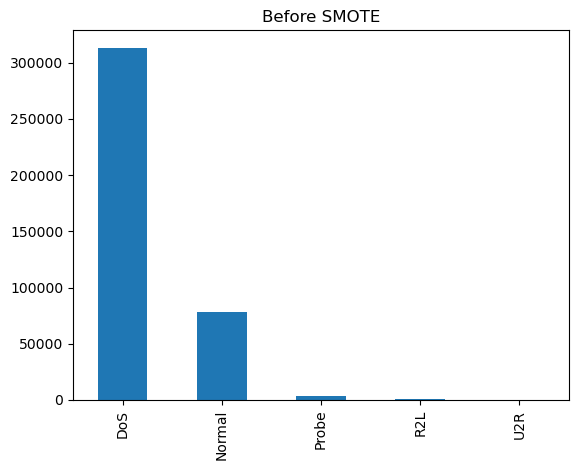

In [ ]:
import matplotlib.pyplot as plt

pd.Series(y_train_orig1).value_counts().plot(kind="bar", title="Before SMOTE")
plt.show()

### After SMOTE

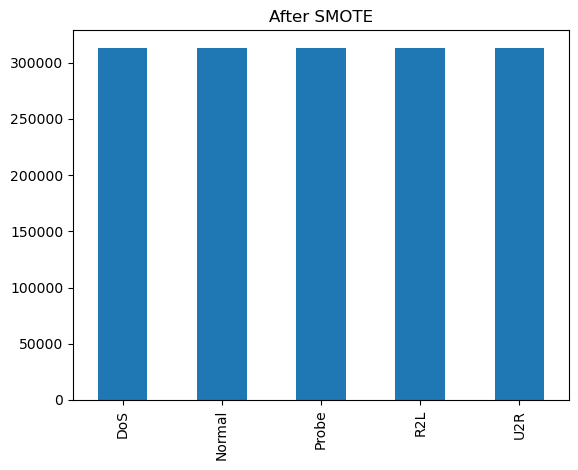

In [ ]:
pd.Series(y_train_smote1).value_counts().plot(kind="bar", title="After SMOTE")
plt.show()

## Re-usable Evaluation Function

In [ ]:
from sklearn.metrics import (

    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt


def evaluate_model(
    name,
    model,
    X_test,
    y_test,
    results_container,
    class_results_container,
    label_encoder
):

    y_pred = model.predict(X_test)

    y_test_display = label_encoder.inverse_transform(y_test)
    y_pred_display = label_encoder.inverse_transform(y_pred)

    class_names = label_encoder.classes_

    # -------------------------
    # Overall Metrics
    # -------------------------

    acc = accuracy_score(y_test, y_pred)

    prec = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    rec = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    results_container.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1
    })

    # -------------------------
    # Display Results
    # -------------------------

    print(f"\n{name}")
    print("-" * 50)
    print(f"Accuracy : {acc:.6f}")
    print(f"Precision: {prec:.6f}")
    print(f"Recall   : {rec:.6f}")
    print(f"F1-score : {f1:.6f}")

    # -------------------------
    # Classification Report
    # -------------------------

    report_dict = classification_report(
        y_test_display,
        y_pred_display,
        labels=class_names,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    print("\nDetailed Classification Report")

    print(
        classification_report(
            y_test_display,
            y_pred_display,
            labels=class_names,
            target_names=class_names,
            zero_division=0
        )
    )

    # -------------------------
    # Save Per-Class Metrics
    # -------------------------

    for cls, vals in report_dict.items():

        if cls in [
            "accuracy",
            "macro avg",
            "weighted avg"
        ]:
            continue

        class_results_container.append({
            "Model": name,
            "Class": cls,
            "Precision": vals["precision"],
            "Recall": vals["recall"],
            "F1-score": vals["f1-score"],
            "Support": vals["support"]
        })

    # -------------------------
    # Confusion Matrix
    # -------------------------

    if label_encoder is not None:

        cm = confusion_matrix(
            y_test_display,
            y_pred_display,
            labels=class_names
        )

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=class_names
        )

    else:

        cm = confusion_matrix(y_test, y_pred)

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm
        )

    fig, ax = plt.subplots(figsize=(6, 5))

    disp.plot(
        ax=ax,
        cmap="YlOrBr",
        xticks_rotation=45
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

## Metrics Bar Plots

In [ ]:
def plot_metrics(results, title):
    df = pd.DataFrame(results, columns=["Accuracy","Precision","Recall","F1"])

    df.plot(kind="bar", figsize=(8,5))
    plt.title(title)
    plt.ylim(0,1)
    plt.xticks(rotation=0)
    plt.grid(axis="y")
    plt.show()


## Result containers

In [ ]:
phase1_results = []
phase1_class_results = []

phase2_results = []
phase2_class_results = []

phase3_results = []
phase3_class_results = []

phase4_results = []
phase4_class_results = []

# Phase 1: Base Paper Reproduction (Imbalanced data)

## 1. Decision Tree Model

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_p1 = DecisionTreeClassifier(
    random_state=SEED
)

dt_p1.fit(X_train_selected, y_train_enc)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None



DT1
--------------------------------------------------
Accuracy : 0.999373
Precision: 0.930716
Recall   : 0.922173
F1-score : 0.926347

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     78292
      Normal       1.00      1.00      1.00     19456
       Probe       0.99      0.99      0.99       822
         R2L       0.97      0.92      0.95       225
         U2R       0.70      0.70      0.70        10

    accuracy                           1.00     98805
   macro avg       0.93      0.92      0.93     98805
weighted avg       1.00      1.00      1.00     98805



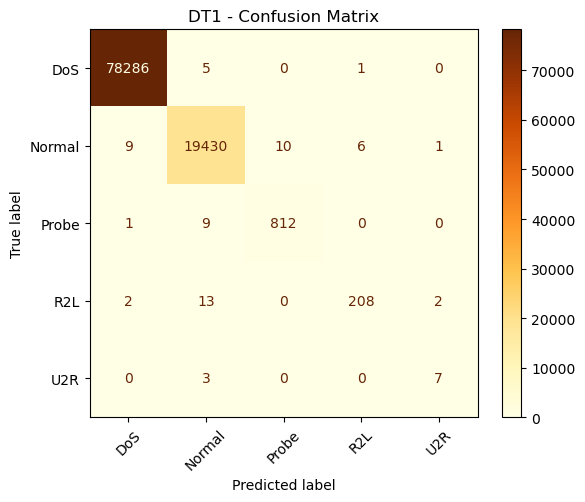

In [ ]:
evaluate_model(
    "DT1", dt_p1,
    X_test_selected,
    y_test_enc,
    phase1_results,
    phase1_class_results,
    label_encoder=label_encoder
)

## 2. Logistic Regression Model

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_p1 = LogisticRegression(
    random_state=SEED
)

lr_p1.fit(X_train_selected, y_train_enc)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'



LR1
--------------------------------------------------
Accuracy : 0.993037
Precision: 0.910502
Recall   : 0.815884
F1-score : 0.843820

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      0.99      1.00     78292
      Normal       0.97      1.00      0.98     19456
       Probe       0.99      0.96      0.98       822
         R2L       0.85      0.83      0.84       225
         U2R       0.75      0.30      0.43        10

    accuracy                           0.99     98805
   macro avg       0.91      0.82      0.84     98805
weighted avg       0.99      0.99      0.99     98805



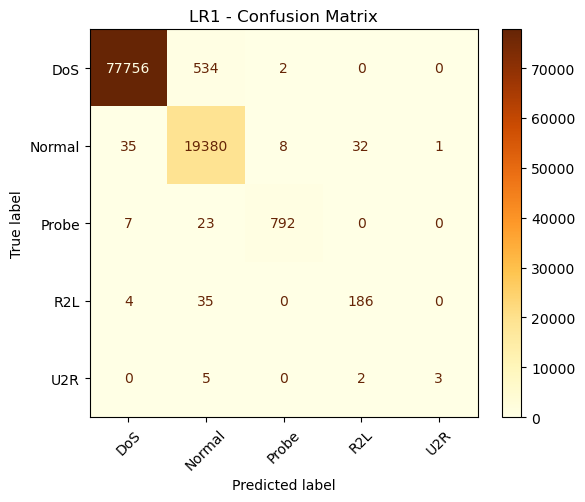

In [ ]:
evaluate_model(
    "LR1", lr_p1,
    X_test_selected,
    y_test_enc,
    phase1_results,
    phase1_class_results,
    label_encoder=label_encoder
)


## 3. Gaussian Naive Bayes Model

In [ ]:
from sklearn.naive_bayes import GaussianNB

gnb_p1 = GaussianNB()

gnb_p1.fit(X_train_selected, y_train_enc)

,priors,None
,var_smoothing,1e-09



GNB1
--------------------------------------------------
Accuracy : 0.951440
Precision: 0.577266
Recall   : 0.816876
F1-score : 0.596592

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      0.99      0.99     78292
      Normal       0.96      0.81      0.88     19456
       Probe       0.68      0.96      0.80       822
         R2L       0.24      0.43      0.31       225
         U2R       0.00      0.90      0.01        10

    accuracy                           0.95     98805
   macro avg       0.58      0.82      0.60     98805
weighted avg       0.99      0.95      0.97     98805



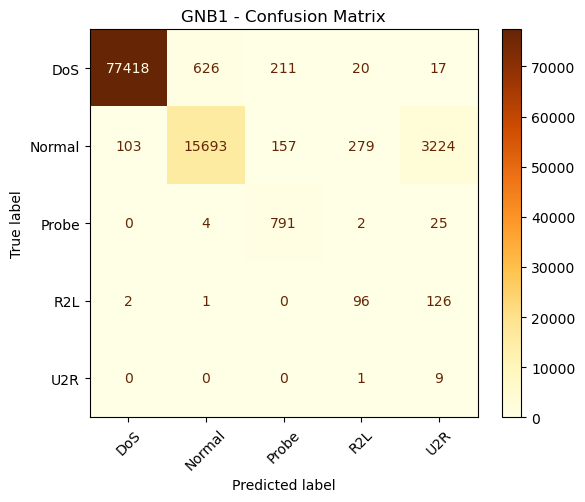

In [ ]:
evaluate_model(
    "GNB1",
    gnb_p1,
    X_test_selected,
    y_test_enc,
    phase1_results,
    phase1_class_results,
    label_encoder=label_encoder
)

## 4. SGD Model

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd_p1 = SGDClassifier(
    random_state=SEED
)

sgd_p1.fit(X_train_smote, y_train_smote)

,loss,'hinge'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None



SGD1
--------------------------------------------------
Accuracy : 0.980679
Precision: 0.615662
Recall   : 0.957908
F1-score : 0.668377

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      0.99      0.99     78292
      Normal       0.96      0.95      0.95     19456
       Probe       0.82      0.98      0.89       822
         R2L       0.21      0.98      0.35       225
         U2R       0.08      0.90      0.15        10

    accuracy                           0.98     98805
   macro avg       0.62      0.96      0.67     98805
weighted avg       0.99      0.98      0.98     98805



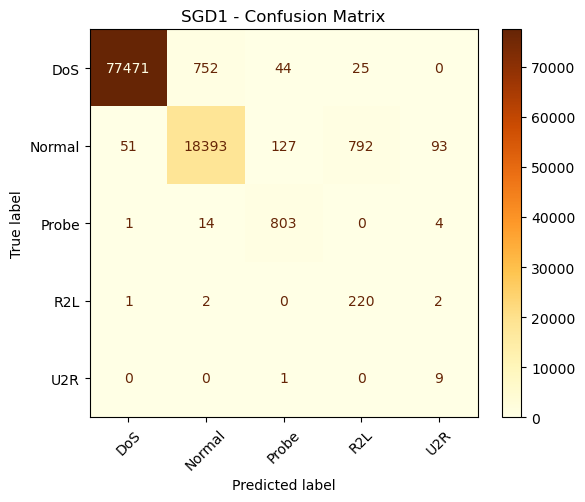

In [ ]:
evaluate_model(
    "SGD1",
    sgd_p1,
    X_test_selected,
    y_test_enc,
    phase1_results,
    phase1_class_results,
    label_encoder=label_encoder
)


## 5. Stacking phase 1 Models

In [ ]:
base_learners_p1 = [
    ("dt1", dt_p1),
    ("lr1", lr_p1),
    ("gnb1", gnb_p1),
    ("sgd1", sgd_p1)
]

In [ ]:
stack_model = StackingClassifier(
    estimators=base_learners_p1,
    final_estimator=SGDClassifier(

        random_state=SEED
    ),
    # stack_method="predict_proba",
    cv=3,          # reduce runtime
    n_jobs=-1
)

stack_model.fit(X_train_selected, y_train_enc)

,estimators,"[('dt1', ...), ('lr1', ...), ...]"
,final_estimator,SGDClassifier(random_state=42)
,cv,3
,stack_method,'auto'
,n_jobs,-1
,passthrough,False
,verbose,0
,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2



Stack1
--------------------------------------------------
Accuracy : 0.999281
Precision: 0.780322
Recall   : 0.785939
F1-score : 0.783098

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     78292
      Normal       1.00      1.00      1.00     19456
       Probe       0.99      0.99      0.99       822
         R2L       0.92      0.94      0.93       225
         U2R       0.00      0.00      0.00        10

    accuracy                           1.00     98805
   macro avg       0.78      0.79      0.78     98805
weighted avg       1.00      1.00      1.00     98805



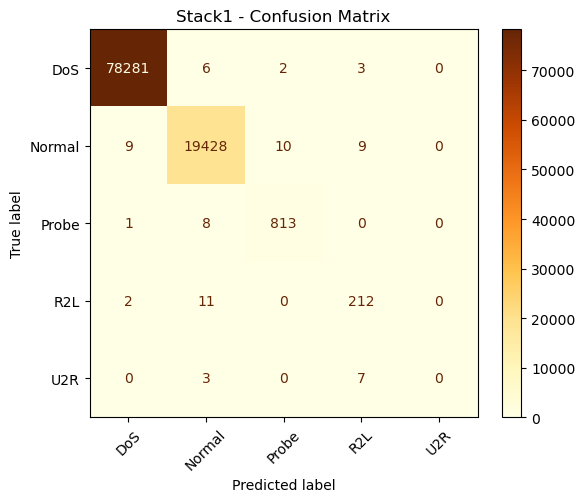

In [ ]:

evaluate_model(
    "Stack1",
    stack_model,
    X_test_selected,
    y_test_enc,
    phase1_results,
    phase1_class_results,
    label_encoder=label_encoder
)

## Summary Table Phase 1

In [ ]:
import pandas as pd

phase1_df = pd.DataFrame(phase1_results)
phase1_df = phase1_df.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)

phase1_df

,Model,Accuracy,Precision,Recall,F1-score
0,DT1,0.999373,0.930716,0.922173,0.926347
1,Stack1,0.999281,0.780322,0.785939,0.783098
2,LR1,0.993037,0.910502,0.815884,0.843820
3,SGD1,0.980679,0.615662,0.957908,0.668377
4,GNB1,0.951440,0.577266,0.816876,0.596592


## Bar Plot Comparison Phase 1

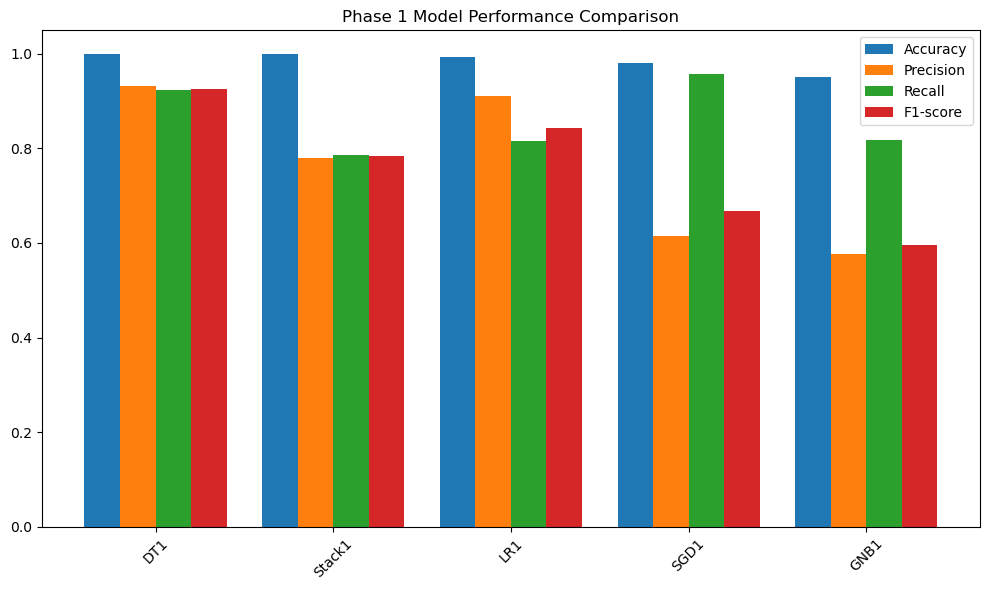

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

x = np.arange(len(phase1_df["Model"]))
width = 0.2

plt.bar(x - 1.5*width, phase1_df["Accuracy"], width, label="Accuracy")
plt.bar(x - 0.5*width, phase1_df["Precision"], width, label="Precision")
plt.bar(x + 0.5*width, phase1_df["Recall"], width, label="Recall")
plt.bar(x + 1.5*width, phase1_df["F1-score"], width, label="F1-score")

plt.xticks(x, phase1_df["Model"], rotation=45)
plt.legend()
plt.title("Phase 1 Model Performance Comparison")
plt.tight_layout()
plt.show()

## Overall Results

In [ ]:
phase1_results_df = pd.DataFrame(phase1_results)

display(
    phase1_results_df.sort_values(
        "Accuracy",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1-score
0,DT1,0.999373,0.930716,0.922173,0.926347
4,Stack1,0.999281,0.780322,0.785939,0.783098
1,LR1,0.993037,0.910502,0.815884,0.843820
3,SGD1,0.980679,0.615662,0.957908,0.668377
2,GNB1,0.951440,0.577266,0.816876,0.596592


## Per-Class Results

In [ ]:
phase1_class_df = pd.DataFrame(
    phase1_class_results
)

display(
    phase1_class_df
)

,Model,Class,Precision,Recall,F1-score,Support
0,DT1,DoS,0.999847,0.999923,0.999885,78292.0
1,DT1,Normal,0.998458,0.998664,0.998561,19456.0
2,DT1,Probe,0.987835,0.987835,0.987835,822.0
3,DT1,R2L,0.967442,0.924444,0.945455,225.0
4,DT1,U2R,0.700000,0.700000,0.700000,10.0
5,LR1,DoS,0.999409,0.993154,0.996271,78292.0
6,LR1,Normal,0.970116,0.996094,0.982933,19456.0
7,LR1,Probe,0.987531,0.963504,0.975369,822.0
8,LR1,R2L,0.845455,0.826667,0.835955,225.0
9,LR1,U2R,0.750000,0.300000,0.428571,10.0


# Phase 2: Base Paper + SMOTE

## 1. Decision Tree Model

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_p2 = DecisionTreeClassifier(
    random_state=SEED
)

dt_p2.fit(X_train_smote, y_train_smote)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None



DT2
--------------------------------------------------
Accuracy : 0.999302
Precision: 0.902149
Recall   : 0.924596
F1-score : 0.912300

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     78292
      Normal       1.00      1.00      1.00     19456
       Probe       0.98      0.99      0.99       822
         R2L       0.95      0.93      0.94       225
         U2R       0.58      0.70      0.64        10

    accuracy                           1.00     98805
   macro avg       0.90      0.92      0.91     98805
weighted avg       1.00      1.00      1.00     98805



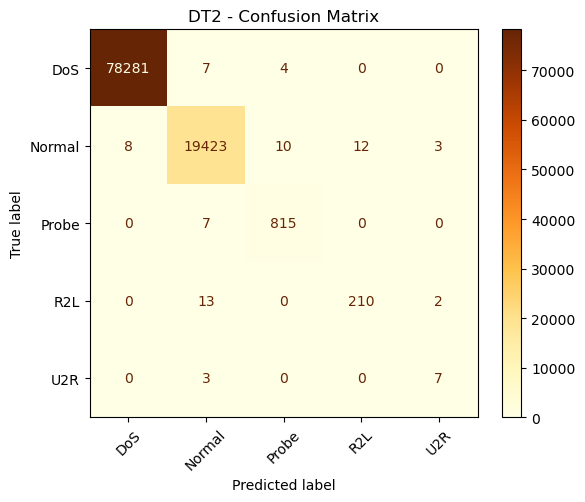

In [ ]:
evaluate_model(
    "DT2",
    dt_p2,
    X_test_selected,
    y_test_enc,
    phase2_results,
    phase2_class_results,
    label_encoder=label_encoder
)

## 2. Logistic Regression Model

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_p2 = LogisticRegression(
    random_state=SEED
)

lr_p2.fit(X_train_smote, y_train_smote)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'



LR2
--------------------------------------------------
Accuracy : 0.984819
Precision: 0.627445
Recall   : 0.949597
F1-score : 0.686540

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      0.99      1.00     78292
      Normal       0.97      0.96      0.96     19456
       Probe       0.81      0.99      0.89       822
         R2L       0.26      0.91      0.41       225
         U2R       0.10      0.90      0.17        10

    accuracy                           0.98     98805
   macro avg       0.63      0.95      0.69     98805
weighted avg       0.99      0.98      0.99     98805



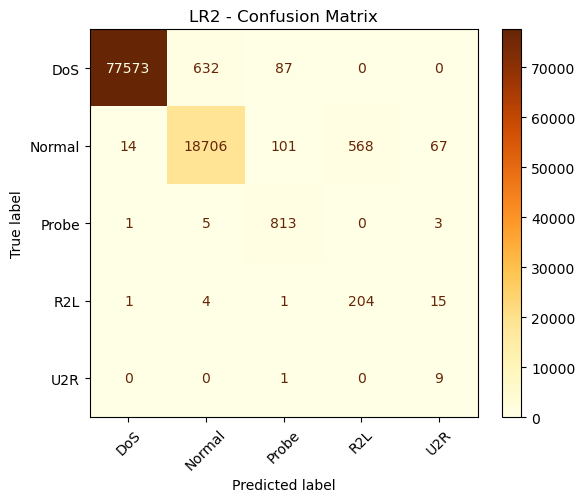

In [ ]:
evaluate_model(
    "LR2",
    lr_p2,
    X_test_selected,
    y_test_enc,
    phase2_results,
    phase2_class_results,
    label_encoder=label_encoder
)

## 3. Gaussian Naive Bayes Model

In [ ]:
from sklearn.naive_bayes import GaussianNB

gnb_p2 = GaussianNB()

gnb_p2.fit(X_train_smote, y_train_smote)

,priors,None
,var_smoothing,1e-09



GNB2
--------------------------------------------------
Accuracy : 0.952108
Precision: 0.573338
Recall   : 0.818783
F1-score : 0.594572

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      0.99      0.99     78292
      Normal       0.97      0.81      0.88     19456
       Probe       0.64      0.97      0.77       822
         R2L       0.26      0.43      0.32       225
         U2R       0.00      0.90      0.01        10

    accuracy                           0.95     98805
   macro avg       0.57      0.82      0.59     98805
weighted avg       0.99      0.95      0.97     98805



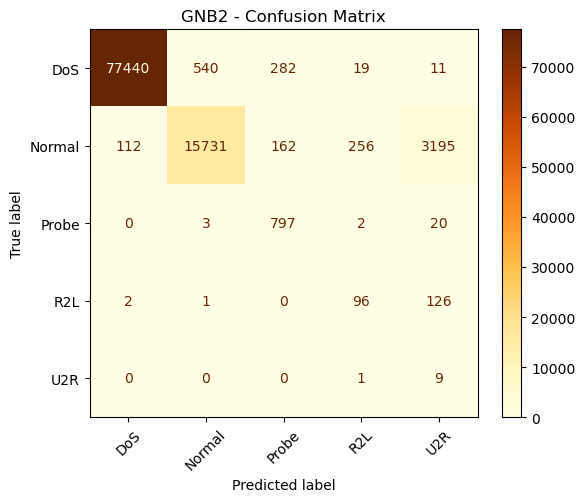

In [ ]:
evaluate_model(
    "GNB2",
    gnb_p2,
    X_test_selected,
    y_test_enc,
    phase2_results,
    phase2_class_results,
    label_encoder=label_encoder
)

## 4. SGD Model

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd_p2 = SGDClassifier(
    random_state=SEED
)

sgd_p2.fit(X_train_smote, y_train_smote)

,loss,'hinge'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None



SGD2
--------------------------------------------------
Accuracy : 0.980679
Precision: 0.615662
Recall   : 0.957908
F1-score : 0.668377

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      0.99      0.99     78292
      Normal       0.96      0.95      0.95     19456
       Probe       0.82      0.98      0.89       822
         R2L       0.21      0.98      0.35       225
         U2R       0.08      0.90      0.15        10

    accuracy                           0.98     98805
   macro avg       0.62      0.96      0.67     98805
weighted avg       0.99      0.98      0.98     98805



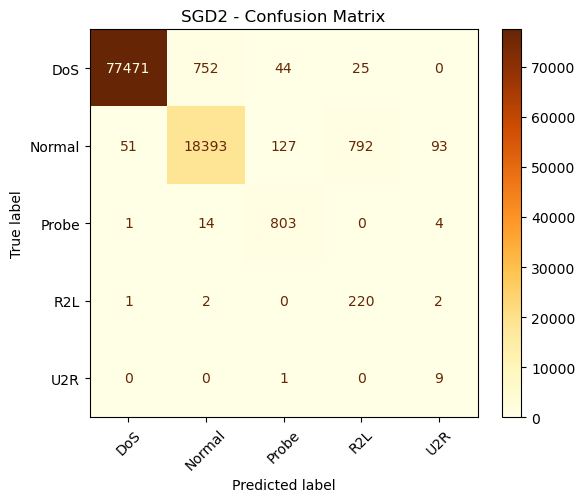

In [ ]:
evaluate_model(
    "SGD2",
    sgd_p2,
    X_test_selected,
    y_test_enc,
    phase2_results,
    phase2_class_results,
    label_encoder=label_encoder
)


## 5. Stacking phase 2 Models

In [ ]:
base_learners_p2 = [
    ("dt2", dt_p2),
    ("lr2", lr_p2),
    ("gnb2", gnb_p2),
    ("sgd2", sgd_p2)
]

In [ ]:
stack_model2 = StackingClassifier(
    estimators=base_learners_p2,
    final_estimator=SGDClassifier(

        random_state=SEED
    ),
    # stack_method="predict_proba",
    cv=3,          # reduce runtime
    n_jobs=-1
)

stack_model2.fit(X_train_smote, y_train_smote)

,estimators,"[('dt2', ...), ('lr2', ...), ...]"
,final_estimator,SGDClassifier(random_state=42)
,cv,3
,stack_method,'auto'
,n_jobs,-1
,passthrough,False
,verbose,0
,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2



Stack2
--------------------------------------------------
Accuracy : 0.999281
Precision: 0.908539
Recall   : 0.944589
F1-score : 0.924144

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     78292
      Normal       1.00      1.00      1.00     19456
       Probe       0.98      0.99      0.99       822
         R2L       0.95      0.93      0.94       225
         U2R       0.62      0.80      0.70        10

    accuracy                           1.00     98805
   macro avg       0.91      0.94      0.92     98805
weighted avg       1.00      1.00      1.00     98805



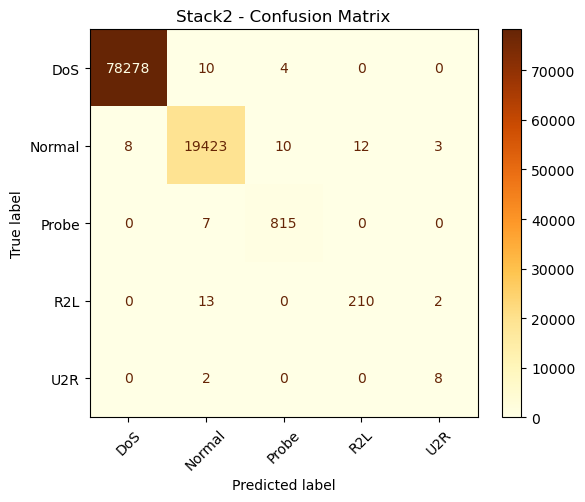

In [ ]:
evaluate_model(
    "Stack2",
    stack_model2,
    X_test_selected,
    y_test_enc,
    phase2_results,
    phase2_class_results,
    label_encoder=label_encoder
)

## Summary Table Phase 2

In [ ]:
phase2_df = pd.DataFrame(phase2_results)
phase2_df = phase2_df.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)

phase2_df

,Model,Accuracy,Precision,Recall,F1-score
0,DT2,0.999302,0.902149,0.924596,0.912300
1,Stack2,0.999281,0.908539,0.944589,0.924144
2,LR2,0.984819,0.627445,0.949597,0.686540
3,SGD2,0.980679,0.615662,0.957908,0.668377
4,GNB2,0.952108,0.573338,0.818783,0.594572


## Bar Plot Comparison Phase 2

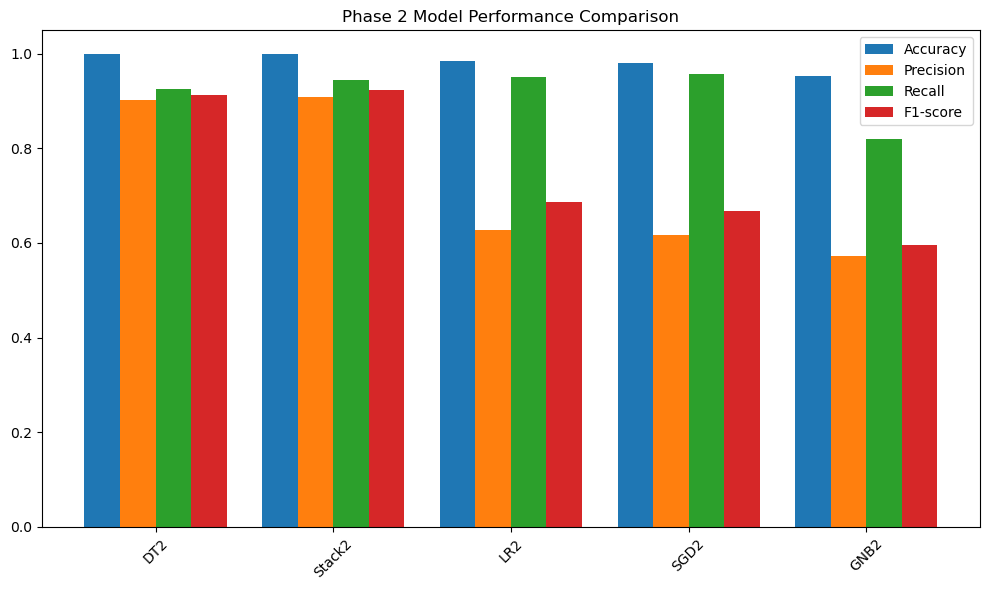

In [ ]:
plt.figure(figsize=(10,6))

x = np.arange(len(phase2_df["Model"]))
width = 0.2

plt.bar(x - 1.5*width, phase2_df["Accuracy"], width, label="Accuracy")
plt.bar(x - 0.5*width, phase2_df["Precision"], width, label="Precision")
plt.bar(x + 0.5*width, phase2_df["Recall"], width, label="Recall")
plt.bar(x + 1.5*width, phase2_df["F1-score"], width, label="F1-score")

plt.xticks(x, phase2_df["Model"], rotation=45)
plt.legend()
plt.title("Phase 2 Model Performance Comparison")
plt.tight_layout()
plt.show()

## Overall results

In [ ]:
phase2_results_df = pd.DataFrame(phase2_results)

display(
    phase2_results_df.sort_values(
        "Accuracy",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1-score
0,DT2,0.999302,0.902149,0.924596,0.912300
4,Stack2,0.999281,0.908539,0.944589,0.924144
1,LR2,0.984819,0.627445,0.949597,0.686540
3,SGD2,0.980679,0.615662,0.957908,0.668377
2,GNB2,0.952108,0.573338,0.818783,0.594572


## Per-class Results

In [ ]:
phase2_class_df = pd.DataFrame(
    phase2_class_results
)

display(
    phase2_class_df
)

,Model,Class,Precision,Recall,F1-score,Support
0,DT2,DoS,0.999898,0.999860,0.999879,78292.0
1,DT2,Normal,0.998458,0.998304,0.998381,19456.0
2,DT2,Probe,0.983112,0.991484,0.987280,822.0
3,DT2,R2L,0.945946,0.933333,0.939597,225.0
4,DT2,U2R,0.583333,0.700000,0.636364,10.0
5,LR2,DoS,0.999794,0.990816,0.995285,78292.0
6,LR2,Normal,0.966868,0.961451,0.964152,19456.0
7,LR2,Probe,0.810568,0.989051,0.890959,822.0
8,LR2,R2L,0.264249,0.906667,0.409228,225.0
9,LR2,U2R,0.095745,0.900000,0.173077,10.0


# Phase 3: Proposed Model (on Imbalanced data)

## 1. Random Forest (Phase 3)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_p3 = RandomForestClassifier(
    n_estimators=10,
    max_depth=None,
    random_state=SEED,
    n_jobs=-1
)

rf_p3.fit(X_train_selected, y_train_enc)

,n_estimators,10
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False



RF3
--------------------------------------------------
Accuracy : 0.999453
Precision: 0.960999
Recall   : 0.880580
F1-score : 0.912199

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     78292
      Normal       1.00      1.00      1.00     19456
       Probe       0.99      0.99      0.99       822
         R2L       0.98      0.91      0.94       225
         U2R       0.83      0.50      0.62        10

    accuracy                           1.00     98805
   macro avg       0.96      0.88      0.91     98805
weighted avg       1.00      1.00      1.00     98805



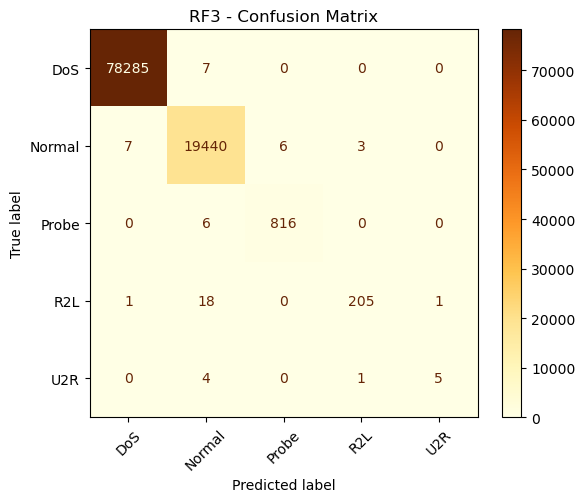

In [ ]:
evaluate_model(
    "RF3",
    rf_p3,
    X_test_selected,
    y_test_enc,
    phase3_results,
    phase3_class_results,
    label_encoder=label_encoder
)

## 2. XGBoost (Phase 3)

In [ ]:
from xgboost import XGBClassifier

xgb_p3 = XGBClassifier(
    n_estimators=10,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    random_state=SEED,
    n_jobs=-1
)

xgb_p3.fit(X_train_selected, y_train_enc)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'mlogloss'



XGB3
--------------------------------------------------
Accuracy : 0.997925
Precision: 0.782076
Recall   : 0.764987
F1-score : 0.773288

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     78292
      Normal       0.99      1.00      1.00     19456
       Probe       0.98      0.95      0.96       822
         R2L       0.94      0.88      0.91       225
         U2R       0.00      0.00      0.00        10

    accuracy                           1.00     98805
   macro avg       0.78      0.76      0.77     98805
weighted avg       1.00      1.00      1.00     98805



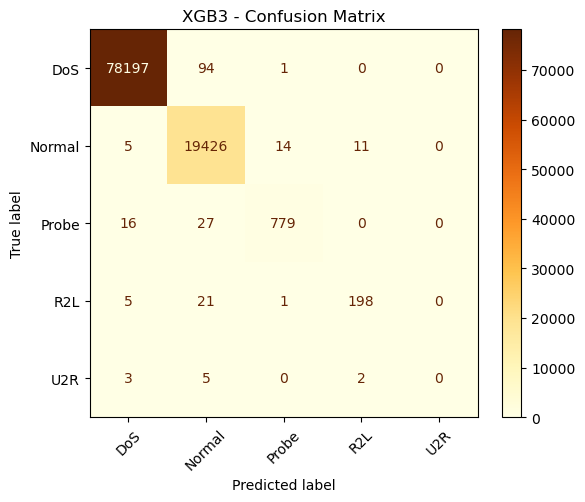

In [ ]:
evaluate_model(
    "XGB3",
    xgb_p3,
    X_test_selected,
    y_test_enc,
    phase3_results,
    phase3_class_results,
    label_encoder=label_encoder
)

## 3. LightGBM (Phase 3)

In [ ]:
from lightgbm import LGBMClassifier

lgbm_p3 = LGBMClassifier(
    n_estimators=10,
    learning_rate=0.1,
    max_depth=-1,
    random_state=SEED,
    n_jobs=-1
)

lgbm_p3.fit(X_train_selected, y_train_enc)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.060529 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1032
[LightGBM] [Info] Number of data points in the train set: 395216, number of used features: 30
[LightGBM] [Info] Start training from score -0.232699
[LightGBM] [Info] Start training from score -1.625008
[LightGBM] [Info] Start training from score -4.790066
[LightGBM] [Info] Start training from score -6.083682
[LightGBM] [Info] Start training from score -9.149518


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,10
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20



LGBM3
--------------------------------------------------
Accuracy : 0.998016
Precision: 0.774769
Recall   : 0.764888
F1-score : 0.769698

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     78292
      Normal       1.00      1.00      1.00     19456
       Probe       0.99      0.99      0.99       822
         R2L       0.89      0.84      0.87       225
         U2R       0.00      0.00      0.00        10

    accuracy                           1.00     98805
   macro avg       0.77      0.76      0.77     98805
weighted avg       1.00      1.00      1.00     98805



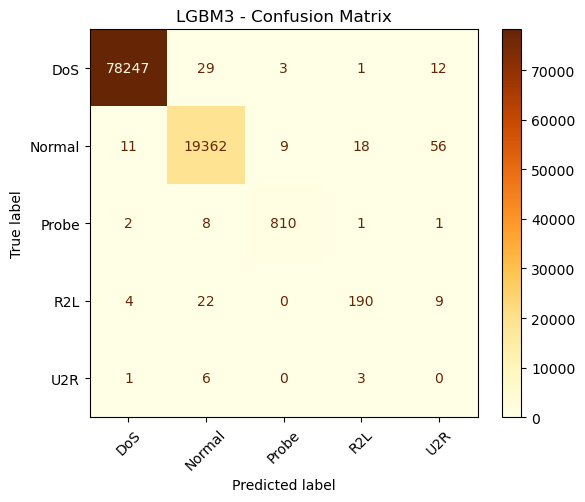

In [ ]:
evaluate_model(
    "LGBM3",
    lgbm_p3,
    X_test_selected,
    y_test_enc,
    phase3_results,
    phase3_class_results,
    label_encoder=label_encoder
)

## 4. LR Model Phase 3

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_p3 = LogisticRegression(
    solver="saga",
    max_iter=1000,
    n_jobs=-1
)

lr_p3.fit(X_train_selected, y_train_enc)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'saga'
,max_iter,1000
,multi_class,'deprecated'



LR3
--------------------------------------------------
Accuracy : 0.993735
Precision: 0.920675
Recall   : 0.832784
F1-score : 0.863264

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      0.99      1.00     78292
      Normal       0.97      1.00      0.98     19456
       Probe       0.98      0.96      0.97       822
         R2L       0.85      0.81      0.83       225
         U2R       0.80      0.40      0.53        10

    accuracy                           0.99     98805
   macro avg       0.92      0.83      0.86     98805
weighted avg       0.99      0.99      0.99     98805



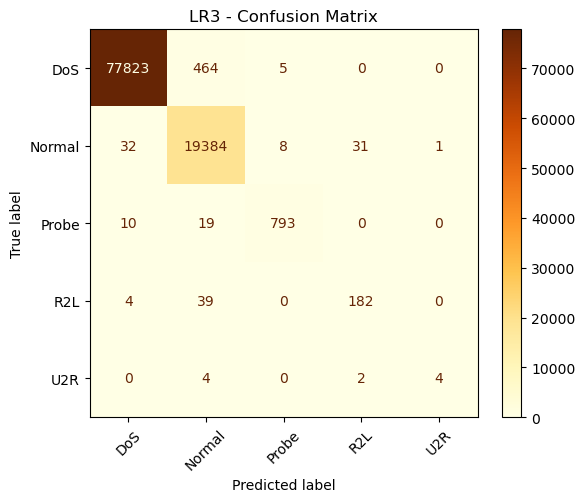

In [ ]:
evaluate_model(
    "LR3",
    lr_p3,
    X_test_selected,
    y_test_enc,
    phase3_results,
    phase3_class_results,
    label_encoder=label_encoder
)

## Stacking Phase 3 Models

In [ ]:
base_learners_p3 = [
    ("rf3", rf_p3),
    ("xgb3", xgb_p3),
    ("lgbm3", lgbm_p3),
    ("lr3", lr_p3)
]

In [ ]:
stack_p3 = StackingClassifier(
    estimators=base_learners_p3,
    final_estimator=LogisticRegression(
        solver="saga",
        max_iter=1000,
        n_jobs=-1
    ),
    stack_method="predict_proba",
    cv=3,          # keeps runtime manageable
    n_jobs=-1
)

stack_p3.fit(X_train_selected, y_train_enc)

,estimators,"[('rf3', ...), ('xgb3', ...), ...]"
,final_estimator,LogisticRegre...solver='saga')
,cv,3
,stack_method,'predict_proba'
,n_jobs,-1
,passthrough,False
,verbose,0
,n_estimators,10
,criterion,'gini'
,max_depth,None
,min_samples_split,2



Stack3
--------------------------------------------------
Accuracy : 0.999453
Precision: 0.994569
Recall   : 0.860590
F1-score : 0.901608

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     78292
      Normal       1.00      1.00      1.00     19456
       Probe       0.99      0.99      0.99       822
         R2L       0.98      0.91      0.94       225
         U2R       1.00      0.40      0.57        10

    accuracy                           1.00     98805
   macro avg       0.99      0.86      0.90     98805
weighted avg       1.00      1.00      1.00     98805



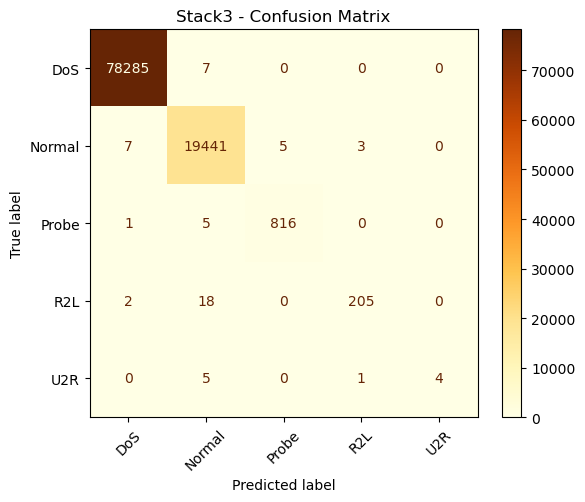

In [ ]:
evaluate_model(
    "Stack3",
    stack_p3,
    X_test_selected,
    y_test_enc,
    phase3_results,
    phase3_class_results,
    label_encoder=label_encoder
)

## Summary Table Phase 3

In [ ]:
import pandas as pd

phase3_df = pd.DataFrame(phase3_results)
phase3_df = phase3_df.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)

phase3_df

,Model,Accuracy,Precision,Recall,F1-score
0,RF3,0.999453,0.960999,0.880580,0.912199
1,Stack3,0.999453,0.994569,0.860590,0.901608
2,LGBM3,0.998016,0.774769,0.764888,0.769698
3,XGB3,0.997925,0.782076,0.764987,0.773288
4,LR3,0.993735,0.920675,0.832784,0.863264


## Bar Plot Comparison Phase 3

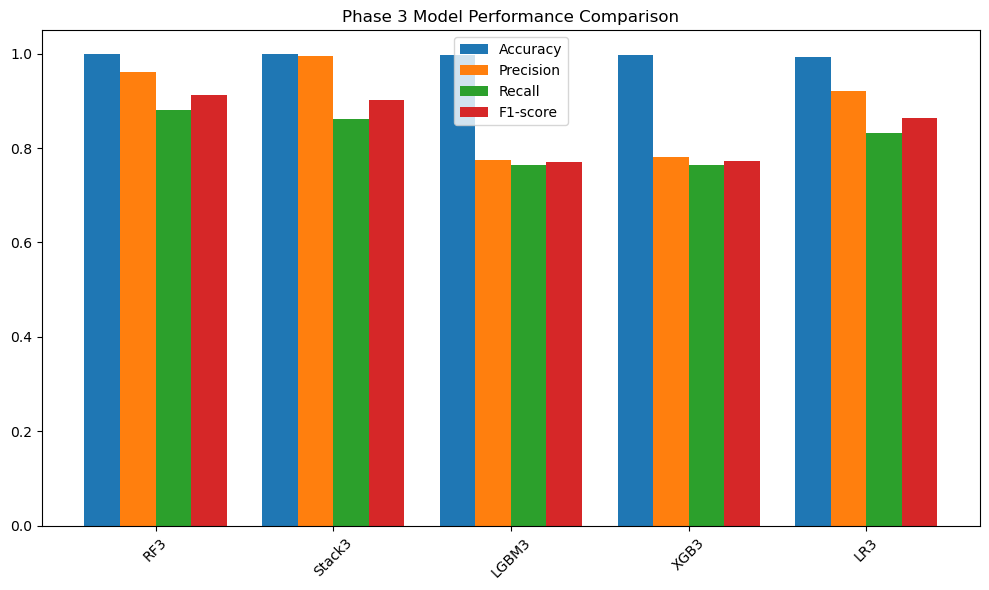

In [ ]:
plt.figure(figsize=(10,6))

x = np.arange(len(phase3_df["Model"]))
width = 0.2

plt.bar(x - 1.5*width, phase3_df["Accuracy"], width, label="Accuracy")
plt.bar(x - 0.5*width, phase3_df["Precision"], width, label="Precision")
plt.bar(x + 0.5*width, phase3_df["Recall"], width, label="Recall")
plt.bar(x + 1.5*width, phase3_df["F1-score"], width, label="F1-score")

plt.xticks(x, phase3_df["Model"], rotation=45)
plt.legend()
plt.title("Phase 3 Model Performance Comparison")
plt.tight_layout()
plt.show()

## Overall results

In [ ]:
phase3_results_df = pd.DataFrame(phase3_results)

display(
    phase3_results_df.sort_values(
        "Accuracy",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1-score
0,RF3,0.999453,0.960999,0.880580,0.912199
4,Stack3,0.999453,0.994569,0.860590,0.901608
2,LGBM3,0.998016,0.774769,0.764888,0.769698
1,XGB3,0.997925,0.782076,0.764987,0.773288
3,LR3,0.993735,0.920675,0.832784,0.863264


## Per-class Results

In [ ]:
phase3_class_df = pd.DataFrame(
    phase3_class_results
)

display(
    phase3_class_df
)

,Model,Class,Precision,Recall,F1-score,Support
0,RF3,DoS,0.999898,0.999911,0.999904,78292.0
1,RF3,Normal,0.998203,0.999178,0.998690,19456.0
2,RF3,Probe,0.992701,0.992701,0.992701,822.0
3,RF3,R2L,0.980861,0.911111,0.944700,225.0
4,RF3,U2R,0.833333,0.500000,0.625000,10.0
5,XGB3,DoS,0.999629,0.998787,0.999208,78292.0
6,XGB3,Normal,0.992490,0.998458,0.995465,19456.0
7,XGB3,Probe,0.979874,0.947689,0.963513,822.0
8,XGB3,R2L,0.938389,0.880000,0.908257,225.0
9,XGB3,U2R,0.000000,0.000000,0.000000,10.0


# Phase 4: Proposed Model + SMOTE

## 1. Random Forest (Phase 4)

In [ ]:
rf_p4 = RandomForestClassifier(
    n_estimators=2,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    bootstrap=True,
    random_state=SEED,
    n_jobs=-1
)

rf_p4.fit(X_train_smote, y_train_smote)

,n_estimators,2
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False



RF_Model
--------------------------------------------------
Accuracy : 0.999322
Precision: 0.943916
Recall   : 0.901441
F1-score : 0.920863

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     78292
      Normal       1.00      1.00      1.00     19456
       Probe       1.00      0.98      0.99       822
         R2L       0.98      0.92      0.95       225
         U2R       0.75      0.60      0.67        10

    accuracy                           1.00     98805
   macro avg       0.94      0.90      0.92     98805
weighted avg       1.00      1.00      1.00     98805



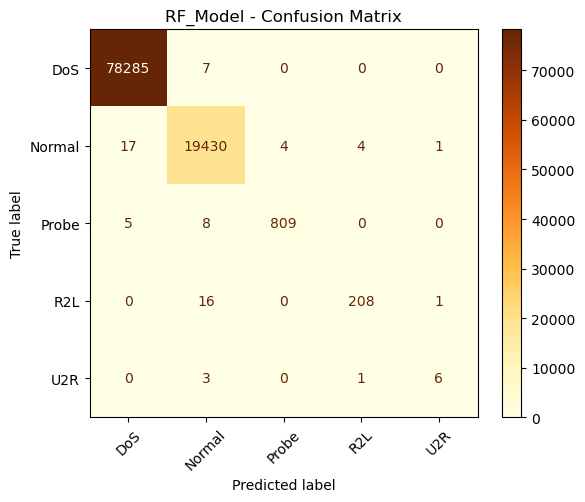

In [ ]:
evaluate_model(
    "RF_Model",
    rf_p4,
    X_test_selected,
    y_test_enc,
    phase4_results,
    phase4_class_results,
    label_encoder=label_encoder
)

## 2. XGBoost (Phase 4)

In [ ]:
xgb_p4 = XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    eval_metric="mlogloss",
    random_state=SEED,
    n_jobs=-1
)

xgb_p4.fit(X_train_smote, y_train_smote)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'mlogloss'



XGB_Model
--------------------------------------------------
Accuracy : 0.999271
Precision: 0.843390
Recall   : 0.949242
F1-score : 0.874387

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     78292
      Normal       1.00      1.00      1.00     19456
       Probe       0.99      1.00      0.99       822
         R2L       0.92      0.95      0.94       225
         U2R       0.31      0.80      0.44        10

    accuracy                           1.00     98805
   macro avg       0.84      0.95      0.87     98805
weighted avg       1.00      1.00      1.00     98805



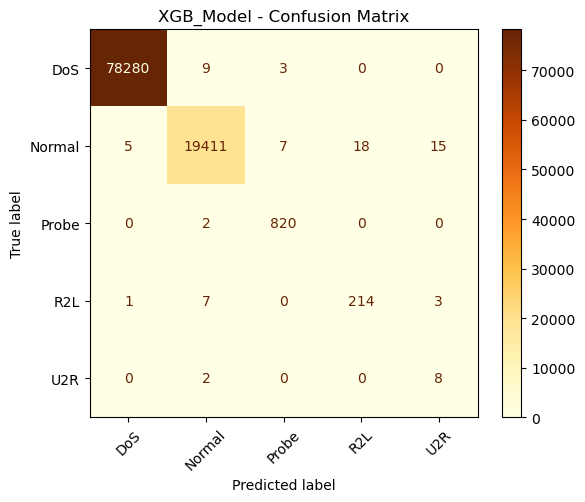

In [ ]:
evaluate_model(
    "XGB_Model",
    xgb_p4,
    X_test_selected,
    y_test_enc,
    phase4_results,
    phase4_class_results,
    label_encoder=label_encoder
)

## 3. LightGBM (Phase 4)

In [ ]:
lgbm_p4 = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=127,
    max_depth=15,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=SEED,
    n_jobs=-1,
    verbosity=-1
)

lgbm_p4.fit(X_train_smote, y_train_smote)

,boosting_type,'gbdt'
,num_leaves,127
,max_depth,15
,learning_rate,0.05
,n_estimators,500
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20



LGBM_Model
--------------------------------------------------
Accuracy : 0.999494
Precision: 0.914924
Recall   : 0.946336
F1-score : 0.928174

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     78292
      Normal       1.00      1.00      1.00     19456
       Probe       0.99      1.00      0.99       822
         R2L       0.97      0.94      0.95       225
         U2R       0.62      0.80      0.70        10

    accuracy                           1.00     98805
   macro avg       0.91      0.95      0.93     98805
weighted avg       1.00      1.00      1.00     98805



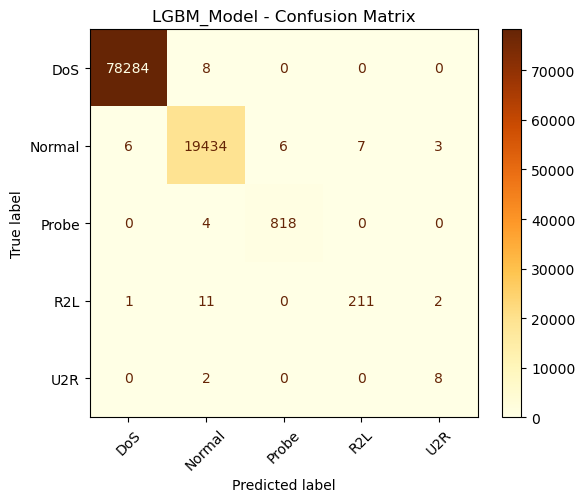

In [ ]:
evaluate_model(
    "LGBM_Model",
    lgbm_p4,
    X_test_selected,
    y_test_enc,
    phase4_results,
    phase4_class_results,
    label_encoder=label_encoder
)

## 4. LR Model Phase 4

In [ ]:
lr_p4 = LogisticRegression(
    solver="saga",
    penalty="l2",
    class_weight="balanced",
    max_iter=3000,
    n_jobs=-1,
    random_state=42
)

lr_p4.fit(X_train_smote, y_train_smote)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'saga'
,max_iter,3000
,multi_class,'deprecated'



LR_Model
--------------------------------------------------
Accuracy : 0.985527
Precision: 0.631784
Recall   : 0.971108
F1-score : 0.692614

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      0.99      1.00     78292
      Normal       0.97      0.96      0.97     19456
       Probe       0.81      0.99      0.89       822
         R2L       0.29      0.91      0.44       225
         U2R       0.10      1.00      0.17        10

    accuracy                           0.99     98805
   macro avg       0.63      0.97      0.69     98805
weighted avg       0.99      0.99      0.99     98805



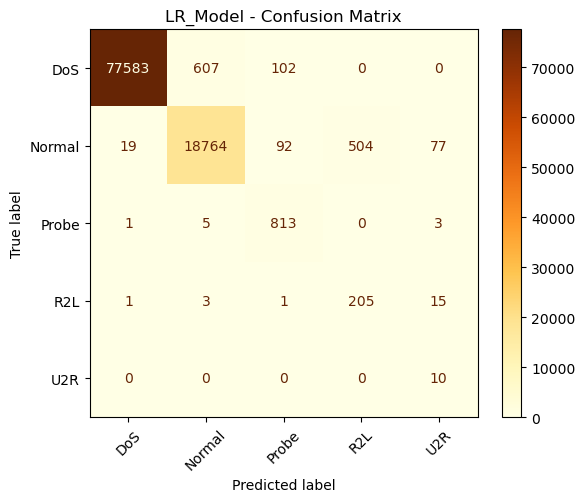

In [ ]:
evaluate_model(
    "LR_Model",
    lr_p4,
    X_test_selected,
    y_test_enc,
    phase4_results,
    phase4_class_results,
    label_encoder=label_encoder
)

## Stacking Phase 4 Models

In [ ]:
base_learners_p4 = [
    ("rf4", rf_p4),
    ("xgb4", xgb_p4),
    ("lgbm4", lgbm_p4),
    ("lr4", lr_p4)
]

In [ ]:
stack_p4 = StackingClassifier(
    estimators=base_learners_p4,

    final_estimator=LogisticRegression(
        solver="saga",
        penalty="l2",
        class_weight="balanced",
        max_iter=3000,
        random_state=SEED,
        n_jobs=-1
    ),

    stack_method="predict_proba",
    cv=3,
    n_jobs=-1
)

stack_p4.fit(X_train_smote, y_train_smote)

,estimators,"[('rf4', ...), ('xgb4', ...), ...]"
,final_estimator,LogisticRegre...solver='saga')
,cv,3
,stack_method,'predict_proba'
,n_jobs,-1
,passthrough,False
,verbose,0
,n_estimators,2
,criterion,'gini'
,max_depth,None
,min_samples_split,2



Improved_Model
--------------------------------------------------
Accuracy : 0.999474
Precision: 0.916401
Recall   : 0.944566
F1-score : 0.927955

Detailed Classification Report
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00     78292
      Normal       1.00      1.00      1.00     19456
       Probe       0.99      1.00      0.99       822
         R2L       0.98      0.93      0.95       225
         U2R       0.62      0.80      0.70        10

    accuracy                           1.00     98805
   macro avg       0.92      0.94      0.93     98805
weighted avg       1.00      1.00      1.00     98805



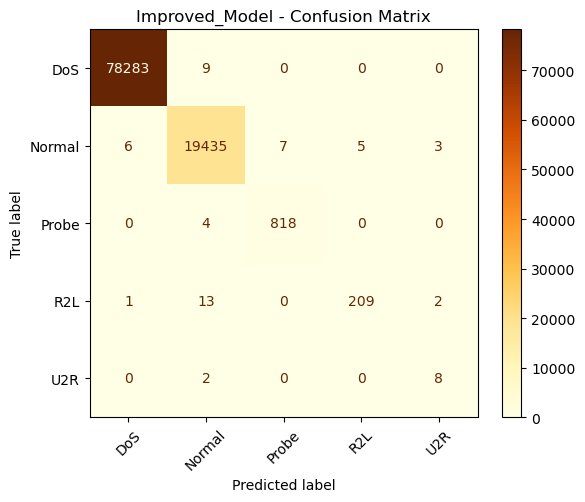

In [ ]:
evaluate_model(
    "Improved_Model",
    stack_p4,
    X_test_selected,
    y_test_enc,
    phase4_results,
    phase4_class_results,
    label_encoder=label_encoder
)

## Overall Results

In [ ]:
phase4_results_df = pd.DataFrame(phase4_results)

display(
    phase4_results_df.sort_values(
        "Accuracy",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1-score
2,LGBM_Model,0.999494,0.914924,0.946336,0.928174
4,Improved_Model,0.999474,0.916401,0.944566,0.927955
0,RF_Model,0.999322,0.943916,0.901441,0.920863
1,XGB_Model,0.999271,0.843390,0.949242,0.874387
3,LR_Model,0.985527,0.631784,0.971108,0.692614


## Per-class results

In [ ]:
phase4_class_df = pd.DataFrame(
    phase4_class_results
)

display(
    phase4_class_df
)

,Model,Class,Precision,Recall,F1-score,Support
0,RF_Model,DoS,0.999719,0.999911,0.999815,78292.0
1,RF_Model,Normal,0.998253,0.998664,0.998458,19456.0
2,RF_Model,Probe,0.995080,0.984185,0.989602,822.0
3,RF_Model,R2L,0.976526,0.924444,0.949772,225.0
4,RF_Model,U2R,0.750000,0.600000,0.666667,10.0
5,XGB_Model,DoS,0.999923,0.999847,0.999885,78292.0
6,XGB_Model,Normal,0.998971,0.997687,0.998328,19456.0
7,XGB_Model,Probe,0.987952,0.997567,0.992736,822.0
8,XGB_Model,R2L,0.922414,0.951111,0.936543,225.0
9,XGB_Model,U2R,0.307692,0.800000,0.444444,10.0


## Summary Table Phase 4

In [ ]:
phase4_df = pd.DataFrame(phase4_results)
phase4_df = phase4_df.sort_values(by="Accuracy", ascending=False).reset_index(drop=True)

phase4_df

,Model,Accuracy,Precision,Recall,F1-score
0,LGBM_Model,0.999494,0.914924,0.946336,0.928174
1,Improved_Model,0.999474,0.916401,0.944566,0.927955
2,RF_Model,0.999322,0.943916,0.901441,0.920863
3,XGB_Model,0.999271,0.843390,0.949242,0.874387
4,LR_Model,0.985527,0.631784,0.971108,0.692614


## Bar Plot Comparison Phase 4

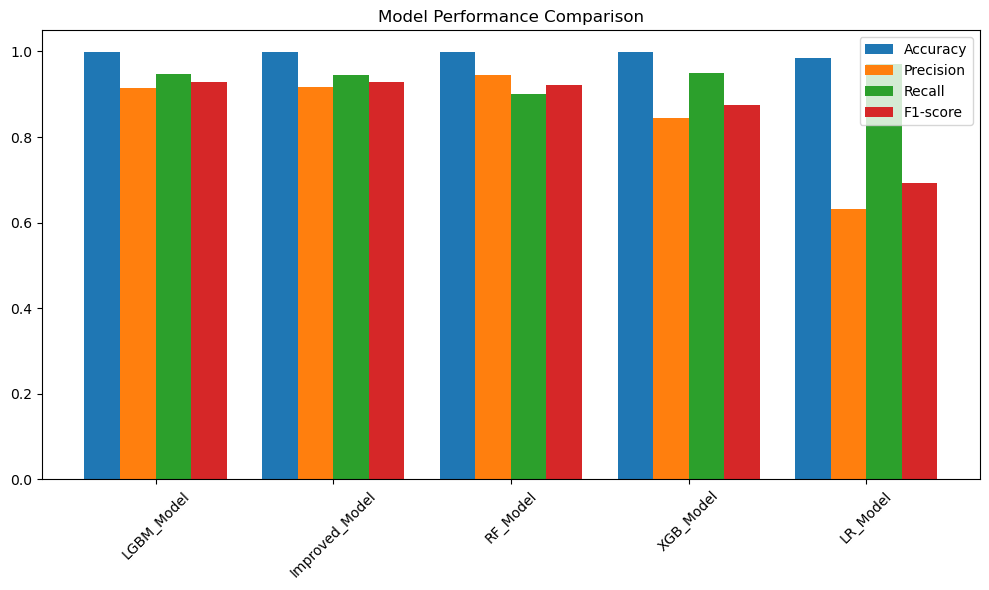

In [ ]:
plt.figure(figsize=(10,6))

x = np.arange(len(phase4_df["Model"]))
width = 0.2

plt.bar(x - 1.5*width, phase4_df["Accuracy"], width, label="Accuracy")
plt.bar(x - 0.5*width, phase4_df["Precision"], width, label="Precision")
plt.bar(x + 0.5*width, phase4_df["Recall"], width, label="Recall")
plt.bar(x + 1.5*width, phase4_df["F1-score"], width, label="F1-score")

plt.xticks(x, phase4_df["Model"], rotation=45)
plt.legend()
plt.title("Model Performance Comparison")
plt.tight_layout()
plt.show()

## Convert All Results Phases into DataFrames

In [ ]:
phase1_df = pd.DataFrame(phase1_results)
phase2_df = pd.DataFrame(phase2_results)
phase3_df = pd.DataFrame(phase3_results)
phase4_df = pd.DataFrame(phase4_results)

phase1_df["Phase"] = "Phase 1"
phase2_df["Phase"] = "Phase 2"
phase3_df["Phase"] = "Phase 3"
phase4_df["Phase"] = "Phase 4"

## Merge Al Result Phases

In [ ]:
all_results_df = pd.concat([phase1_df, phase2_df, phase3_df, phase4_df], ignore_index=True)

all_results_df

,Model,Accuracy,Precision,Recall,F1-score,Phase
0,DT1,0.999373,0.930716,0.922173,0.926347,Phase 1
1,LR1,0.993037,0.910502,0.815884,0.843820,Phase 1
2,GNB1,0.951440,0.577266,0.816876,0.596592,Phase 1
3,SGD1,0.980679,0.615662,0.957908,0.668377,Phase 1
4,Stack1,0.999281,0.780322,0.785939,0.783098,Phase 1
5,DT2,0.999302,0.902149,0.924596,0.912300,Phase 2
6,LR2,0.984819,0.627445,0.949597,0.686540,Phase 2
7,GNB2,0.952108,0.573338,0.818783,0.594572,Phase 2
8,SGD2,0.980679,0.615662,0.957908,0.668377,Phase 2
9,Stack2,0.999281,0.908539,0.944589,0.924144,Phase 2


## Sort all Results by Best Model

In [ ]:
all_results_df = all_results_df.sort_values(by="Accuracy", ascending=False)

all_results_df

,Model,Accuracy,Precision,Recall,F1-score,Phase
17,LGBM_Model,0.999494,0.914924,0.946336,0.928174,Phase 4
19,Improved_Model,0.999474,0.916401,0.944566,0.927955,Phase 4
14,Stack3,0.999453,0.994569,0.860590,0.901608,Phase 3
10,RF3,0.999453,0.960999,0.880580,0.912199,Phase 3
0,DT1,0.999373,0.930716,0.922173,0.926347,Phase 1
15,RF_Model,0.999322,0.943916,0.901441,0.920863,Phase 4
5,DT2,0.999302,0.902149,0.924596,0.912300,Phase 2
9,Stack2,0.999281,0.908539,0.944589,0.924144,Phase 2
4,Stack1,0.999281,0.780322,0.785939,0.783098,Phase 1
16,XGB_Model,0.999271,0.843390,0.949242,0.874387,Phase 4


## Performance Comparison Plot

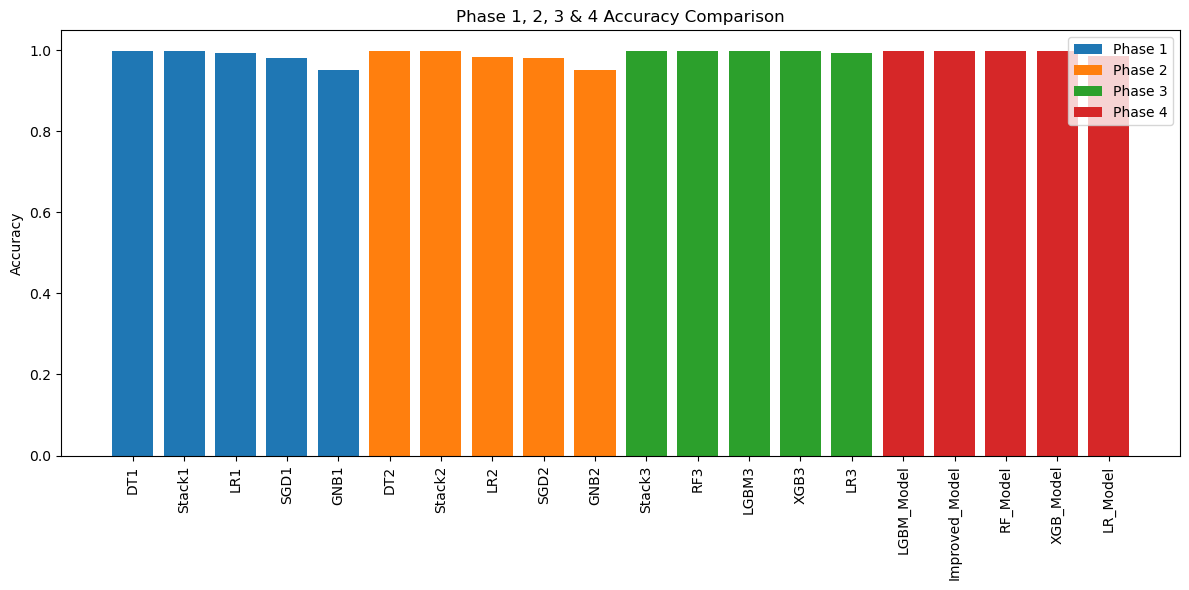

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

for phase, data in all_results_df.groupby("Phase"):
    plt.bar(
        data["Model"],
        data["Accuracy"],
        label=phase
    )

plt.xticks(rotation=90)
plt.ylabel("Accuracy")
plt.title("Phase 1, 2, 3 & 4 Accuracy Comparison")
plt.legend()
plt.tight_layout()

plt.show()

## Multi-Metric Comparison Plot

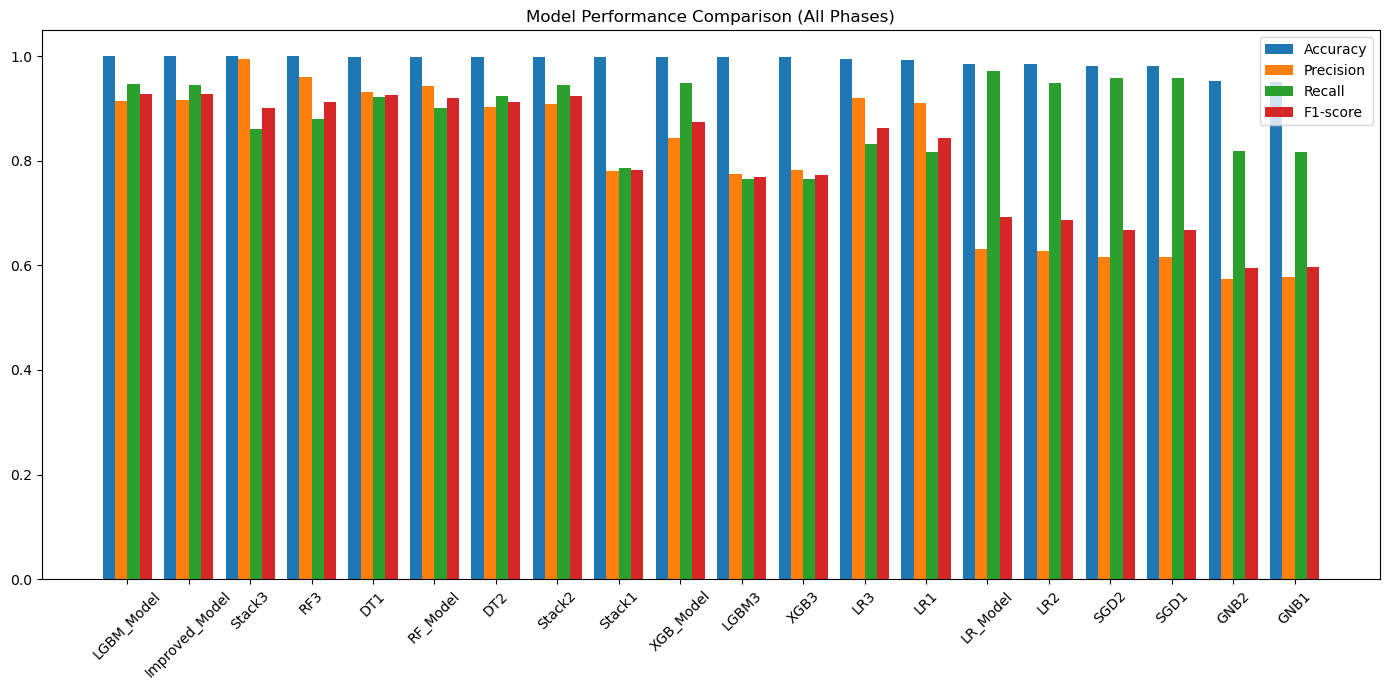

In [ ]:
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

plt.figure(figsize=(14,7))

x = np.arange(len(all_results_df["Model"]))
width = 0.2

for i, metric in enumerate(metrics):
    plt.bar(
        x + i*width,
        all_results_df[metric],
        width,
        label=metric
    )

plt.xticks(x + width*1.5, all_results_df["Model"], rotation=45)
plt.legend()
plt.title("Model Performance Comparison (All Phases)")
plt.tight_layout()

plt.show()

## Best Model Per Phase

In [ ]:
best_phase1 = phase1_df.loc[phase1_df["Accuracy"].idxmax()]
best_phase2 = phase2_df.loc[phase2_df["Accuracy"].idxmax()]
best_phase3 = phase3_df.loc[phase3_df["Accuracy"].idxmax()]
best_phase4 = phase4_df.loc[phase4_df["Accuracy"].idxmax()]

print("Best Phase 1 Model")
print(best_phase1)

print("\nBest Phase 2 Model")
print(best_phase2)

print("\nBest Phase 3 Model")
print(best_phase3)

print("\nBest Phase 4 Model")
print(best_phase4)

Best Phase 1 Model
Model             DT1
Accuracy     0.999373
Precision    0.930716
Recall       0.922173
F1-score     0.926347
Phase         Phase 1
Name: 0, dtype: object

Best Phase 2 Model
Model             DT2
Accuracy     0.999302
Precision    0.902149
Recall       0.924596
F1-score       0.9123
Phase         Phase 2
Name: 0, dtype: object

Best Phase 3 Model
Model             RF3
Accuracy     0.999453
Precision    0.960999
Recall        0.88058
F1-score     0.912199
Phase         Phase 3
Name: 0, dtype: object

Best Phase 4 Model
Model        LGBM_Model
Accuracy       0.999494
Precision      0.914924
Recall         0.946336
F1-score       0.928174
Phase           Phase 4
Name: 2, dtype: object


# Statistical Tests

# 2. McNemar Test (Phase 3 vs Phase 4)

In [ ]:
y_pred_p3 = stack_p3.predict(X_test_proc)
y_pred_p4 = stack_p4.predict(X_test_proc)

In [ ]:
print(len(y_pred_p3), len(y_pred_p4), len(y_test_enc))

98805 98805 98805


In [ ]:
import numpy as np
from statsmodels.stats.contingency_tables import mcnemar

correct_p3 = (y_pred_p3 == y_test_enc).astype(int)
correct_p4 = (y_pred_p4 == y_test_enc).astype(int)

n11 = np.sum((correct_p3 == 1) & (correct_p4 == 1))
n00 = np.sum((correct_p3 == 0) & (correct_p4 == 0))
n01 = np.sum((correct_p3 == 1) & (correct_p4 == 0))
n10 = np.sum((correct_p3 == 0) & (correct_p4 == 1))

table = [[n11, n01],
         [n10, n00]]

print("Contingency Table:")
print(table)

result = mcnemar(table, exact=True)

print("\nn01 (P3 correct, P4 wrong):", n01)
print("n10 (P3 wrong, P4 correct):", n10)
print("McNemar p-value:", result.pvalue)

Contingency Table:
[[np.int64(98740), np.int64(11)], [np.int64(13), np.int64(41)]]

n01 (P3 correct, P4 wrong): 11
n10 (P3 wrong, P4 correct): 13
McNemar p-value: 0.8388197422027588


# Comparison with Existing Papers

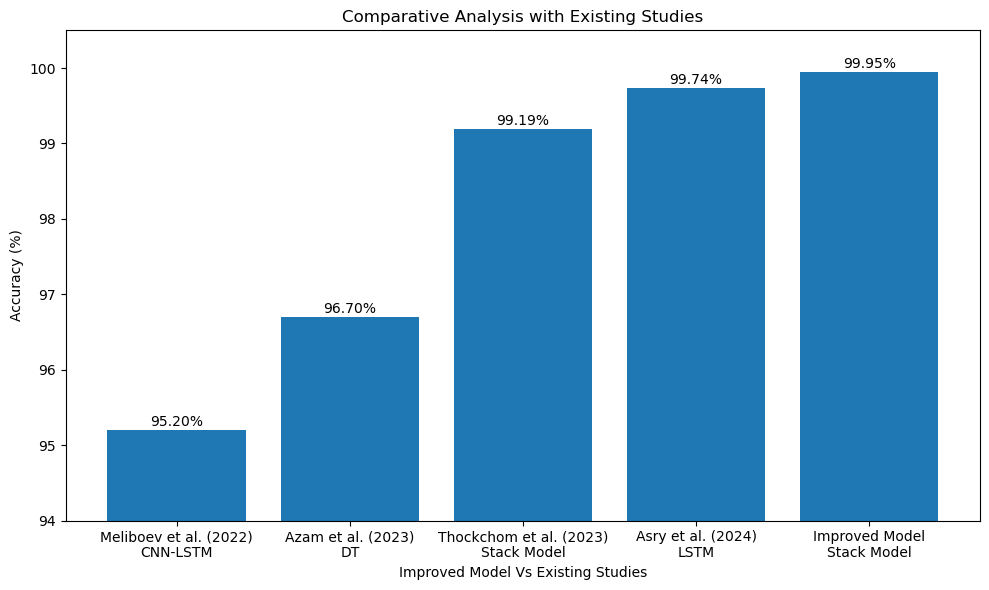

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Study": [
        "Meliboev et al. (2022)\nCNN-LSTM",
        "Thockchom et al. (2023)\nStack Model",
        "Azam et al. (2023)\nDT",
        "Asry et al. (2024)\nLSTM",
        "Improved Model\nStack Model"
    ],
    "Accuracy": [95.20, 99.19, 96.70, 99.74, 99.95]
})

# Sort in descending order
df = df.sort_values(by="Accuracy", ascending=True)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    df["Study"],
    df["Accuracy"]
)

# Add value labels above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.05,
        f"{height:.2f}%",
        ha="center"
    )

plt.ylabel("Accuracy (%)")
plt.xlabel("Improved Model Vs Existing Studies")
plt.title("Comparative Analysis with Existing Studies")

plt.ylim(94, 100.5)

plt.tight_layout()
plt.show()

# ✅ THE END